In [1]:
from google.colab import drive; drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/c2_htr'
!pip -q install pymupdf jiwer datasets
import os, glob, math, json, random, unicodedata
import cv2, numpy as np, pandas as pd, torch, torch.nn as nn

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 113.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 81.5 MB/s eta 0:00:00


In [ ]:
!ls -lh "/content/drive/MyDrive/c2_htr/raw_pdfs"

total 33M
-rw------- 1 root root 2.6M Oct 21 06:18 'CamScanner 08-25-2026 12.04.pdf'
-rw------- 1 root root  18M Oct 21 06:18 'CamScanner 10-02-2026 10.07.pdf'
-rw------- 1 root root  12M Oct 21 06:18 'CamScanner 10-02-2026 10.31.pdf'


In [ ]:
import fitz
os.makedirs(f'{ROOT}/pages', exist_ok=True)
for pdf in glob.glob(f'{ROOT}/raw_pdfs/*.pdf'):
    stem = os.path.splitext(os.path.basename(pdf))[0].replace(' ', '_').replace('.', '_')
    for i, page in enumerate(fitz.open(pdf), 1):
        try:
            page.get_pixmap(dpi=200, colorspace=fitz.csGRAY).save(f'{ROOT}/pages/{stem}_p{i:03d}.png')
        except Exception as e:
            print('skip', stem, i, e)
print(len(glob.glob(f'{ROOT}/pages/*.png')), 'pages')

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


129 pages


In [ ]:
def binarize(g):
    return cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 12)

def deskew(g):
    b = binarize(g); h, w = g.shape
    segs = cv2.HoughLinesP(b, 1, np.pi/720, 150, minLineLength=int(.2*w), maxLineGap=25)
    if segs is None: return g
    a = [math.degrees(math.atan2(y2-y1, x2-x1)) for x1, y1, x2, y2 in np.asarray(segs).reshape(-1, 4)]
    a = [x for x in a if abs(x) < 10]
    if not a: return g
    M = cv2.getRotationMatrix2D((w/2, h/2), float(np.median(a)), 1)
    return cv2.warpAffine(g, M, (w, h), borderValue=255)

def remove_rules(b):
    h, w = b.shape
    hor = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (w//8, 1)))
    ver = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, h//8)))
    return cv2.subtract(b, cv2.dilate(hor | ver, np.ones((3, 3), np.uint8))), ver

def column_bounds(ver, w):
    cov = (ver > 0).mean(0); xs, x = [], 0
    while x < w:
        if cov[x] > 0.3:
            s = x
            while x < w and cov[x] > 0.1: x += 1
            xs.append((s + x)//2)
        x += 1
    cuts = [0] + [x for x in xs if 0.03*w < x < 0.97*w] + [w]
    return [(cuts[i], cuts[i+1]) for i in range(len(cuts)-1) if cuts[i+1] - cuts[i] > 40]

def line_boxes(clean, x0, x1, min_h=15, pad=8):
    strip = clean[:, x0:x1]
    prof = np.convolve((strip > 0).sum(1), np.ones(9)/9, 'same')
    if prof.max() == 0: return []
    on, out, y, H = prof > max(3, 0.08*prof.max()), [], 0, len(prof)
    while y < H:
        if on[y]:
            s = y
            while y < H and on[y]: y += 1
            if y - s >= min_h:
                ys, ye = max(0, s-pad), min(H, y+pad)
                cols = np.where(strip[ys:ye].sum(0) > 0)[0]
                if len(cols) > 20:
                    out.append((x0 + max(0, cols[0]-pad), ys, x0 + min(x1-x0, cols[-1]+pad), ye))
        y += 1
    return out


In [ ]:
os.makedirs(f'{ROOT}/lines', exist_ok=True); rows = []
for p in sorted(glob.glob(f'{ROOT}/pages/*.png')):
    g = deskew(cv2.imread(p, 0)); clean, ver = remove_rules(binarize(g))
    stem = os.path.basename(p)[:-4]
    for ci, (x0, x1) in enumerate(column_bounds(ver, g.shape[1])):
        for li, (xa, ya, xb, yb) in enumerate(line_boxes(clean, x0, x1)):
            name = f'{stem}_c{ci}_l{li:02d}.png'
            cv2.imwrite(f'{ROOT}/lines/{name}', g[ya:yb, xa:xb])
            rows.append(dict(file=name, page=stem, col=ci, text='', status=''))
pd.DataFrame(rows).to_csv(f'{ROOT}/labels.csv', index=False)
print(len(rows), 'line crops')

8585 line crops


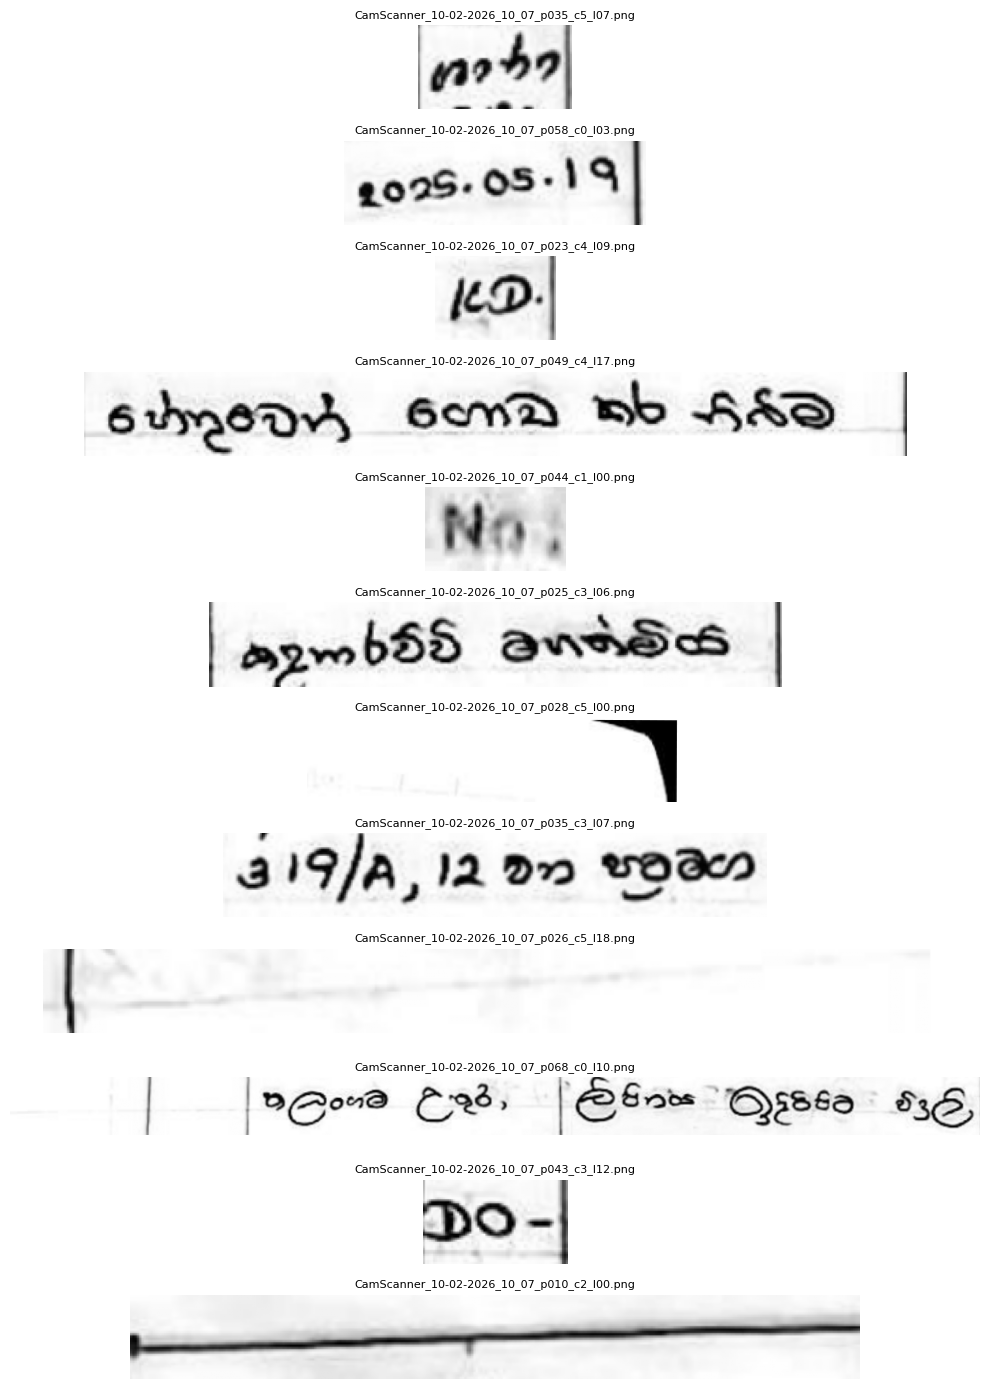

In [ ]:
import matplotlib.pyplot as plt
sample = random.sample(rows, 12)
fig, axes = plt.subplots(12, 1, figsize=(10, 14))
for ax, r in zip(axes, sample):
    ax.imshow(cv2.imread(f"{ROOT}/lines/{r['file']}", 0), cmap='gray'); ax.set_title(r['file'], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
df = pd.read_csv(f'{ROOT}/labels.csv', dtype=str, keep_default_na=False)

def stroke_count(path):
    g = cv2.imread(path, 0); h, w = g.shape
    if (g < 60).mean() > 0.25: return 0                     # big black area = scanner border
    b = binarize(g)
    hor = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (max(15, w//6), 1)))
    ver = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, max(15, int(h*0.8)))))
    t = cv2.subtract(b, cv2.dilate(hor | ver, np.ones((3, 3), np.uint8)))
    n, lab, st, _ = cv2.connectedComponentsWithStats(t)
    return sum(1 for s in st[1:] if s[4] >= 30 and s[3] >= 0.25*h)   # blobs big enough to be letters

from tqdm.auto import tqdm
df['strokes'] = [stroke_count(f"{ROOT}/lines/{f}") for f in tqdm(df.file)]
df['h'] = [cv2.imread(f"{ROOT}/lines/{f}", 0).shape[0] for f in df.file]
med_h = df.h.median()
df.loc[df.strokes < 2, 'status'] = 'auto_junk'
df.loc[(df.status == '') & (df.h > 2.2*med_h), 'status'] = 'auto_multi'
print(df.status.replace('', 'to_label').value_counts())
df.drop(columns=['strokes', 'h']).to_csv(f'{ROOT}/labels.csv', index=False)

  0%|          | 0/8585 [00:00<?, ?it/s]

status
to_label      5917
auto_junk     2157
auto_multi     511
Name: count, dtype: int64


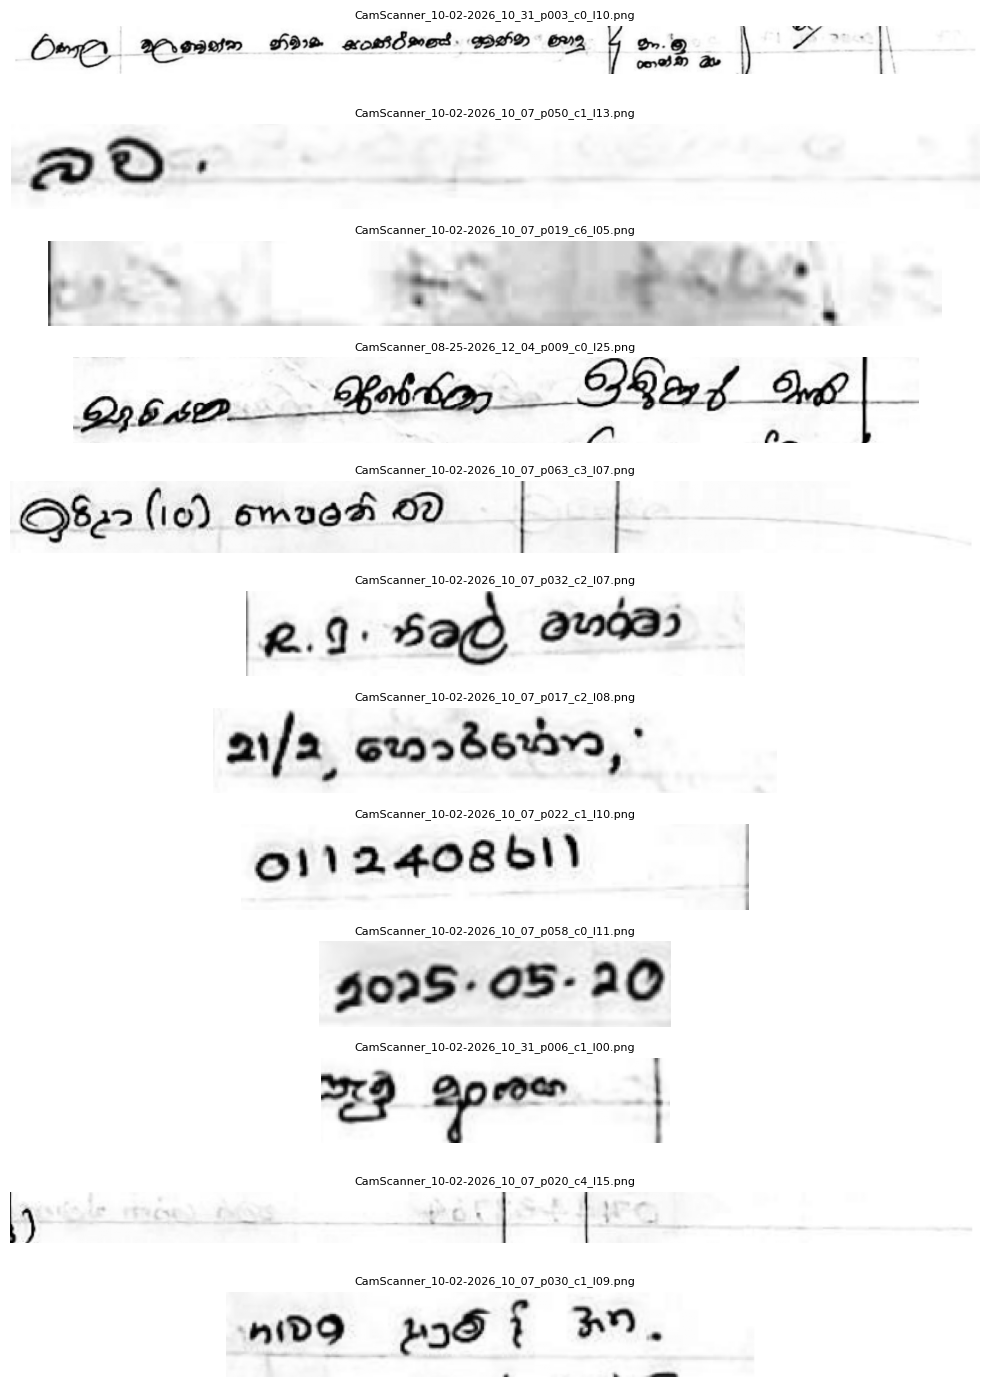

In [ ]:
left = df[df.status == ''].sample(12, random_state=1)
fig, axes = plt.subplots(12, 1, figsize=(10, 14))
for ax, f in zip(axes, left.file):
    ax.imshow(cv2.imread(f"{ROOT}/lines/{f}", 0), cmap='gray'); ax.set_title(f, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
import ipywidgets as W, re
from IPython.display import display

LAB = f'{ROOT}/labels.csv'
df = pd.read_csv(LAB, dtype=str, keep_default_na=False)

# --- queue: 25 pages spread across all PDFs, 20 lines each, in reading order ---
pages_all = sorted(df.page.unique())
chosen = pages_all[::max(1, len(pages_all)//25)][:25]
todo = []
for p in chosen:
    done_here = ((df.page == p) & df.status.isin(['ok', 'pii', 'bad'])).sum()
    idx = list(df.index[(df.page == p) & (df.status == '')])
    random.Random(0).shuffle(idx)
    todo += sorted(idx[:max(0, 20 - done_here)])
pos = 0
print(len(todo), 'lines left in queue | labelled so far:', (df.status == 'ok').sum())

# --- widgets ---
info = W.HTML()
img = W.Image(layout=W.Layout(max_width='100%'))
ref = W.Textarea(placeholder='Paste the whole complaint here (stays while you move between lines)',
                 layout=W.Layout(width='100%', height='110px'))
txt = W.Textarea(placeholder='Type or paste the text of THIS line only',
                 layout=W.Layout(width='100%', height='60px'))

def clean(s):
    s = unicodedata.normalize('NFC', s)
    s = re.sub(r'[\u200b\u200e\u200f\ufeff]', '', s)   # invisible marks from copy-paste (keeps Sinhala joiner \u200d)
    return ' '.join(s.split())                          # one line, single spaces

def show():
    i = todo[pos]
    img.value = open(f"{ROOT}/lines/{df.at[i, 'file']}", 'rb').read()
    txt.value = df.at[i, 'text']                        # shows the old text if you went Back
    done = (df.status == 'ok').sum()
    info.value = f"<b>{pos+1}/{len(todo)}</b> &nbsp; {df.at[i, 'file']} &nbsp; | &nbsp; labelled so far: <b>{done}</b>"

def save(status):
    global pos
    i = todo[pos]
    text = clean(txt.value)
    if status == 'ok' and not text:
        info.value = '<b style="color:red">Type the text first, or use Skip / Bad crop</b>'; return
    df.at[i, 'text'] = text if status == 'ok' else ''
    df.at[i, 'status'] = status
    df.to_csv(LAB, index=False)
    pos += 1
    if pos < len(todo): show()
    else: info.value = '<b>All queued lines done 🎉 Re-run this cell to queue more.</b>'

def back(_):
    global pos
    if pos > 0:
        pos -= 1; show()

btns = [W.Button(description='Save ✓', button_style='success'),
        W.Button(description='Skip: name/phone (PII)'),
        W.Button(description='Bad crop / unreadable')]
for b, s in zip(btns, ['ok', 'pii', 'bad']):
    b.on_click(lambda _, s=s: save(s))
b_back = W.Button(description='← Back'); b_back.on_click(back)

display(W.HTML('<b>Reference text</b> (optional)'), ref, info, img, txt, W.HBox([b_back] + btns))
show()

131 lines left in queue | labelled so far: 306


HTML(value='<b>Reference text</b> (optional)')

Textarea(value='', layout=Layout(height='110px', width='100%'), placeholder='Paste the whole complaint here (s…

HTML(value='')

Image(value=b'', layout="Layout(max_width='100%')")

Textarea(value='', layout=Layout(height='60px', width='100%'), placeholder='Type or paste the text of THIS lin…

IndexError: list index out of range

IndexError: list index out of range

In [ ]:
df = pd.read_csv(f'{ROOT}/labels.csv', dtype=str, keep_default_na=False)
bad = (df.status == 'ok') & (df.text.str.strip().isin(['', 'CamScanner', 'amScanner']))
df.loc[bad, 'status'] = 'bad'
df.to_csv(f'{ROOT}/labels.csv', index=False)
ok = df[df.status == 'ok']
print('usable labelled lines:', len(ok), '| pages:', ok.page.nunique())
print(ok.sample(5, random_state=0)[['file', 'text']].to_string())

usable labelled lines: 362 | pages: 25
                                             file                  text
4195  CamScanner_10-02-2026_10_07_p038_c4_l08.png                 11/12
6654  CamScanner_10-02-2026_10_07_p068_c0_l06.png            අතුරුගිරිය
318   CamScanner_08-25-2026_12_04_p011_c0_l18.png    අපේක්ෂා රෝහල මහරගම
163   CamScanner_08-25-2026_12_04_p006_c0_l10.png           පාර No 52/1
4978  CamScanner_10-02-2026_10_07_p048_c2_l26.png  448, ෂෙල්ටන් පිළිහේන


In [2]:
!cp -r "/content/drive/MyDrive/c2_htr/lines" /content/lines
LINES = '/content/lines'

In [3]:
from datasets import load_dataset
ds = load_dataset("Ransaka/sinhala_synthetic_ocr-large", split="train")
print(ds)
print(ds[0])

README.md:   0%|          | 0.00/728 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  456MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6969 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'text'],
    num_rows: 6969
})
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=2600x128 at 0x7B6CBEE01400>, 'text': 'ඔහු සතුව තිබී හෙරොයින් කිලෝග්රෑම් 1ක් සොයා ගත් අතර ඔහු'}


In [4]:
IMG_COL, TXT_COL = 'image', 'text'
os.makedirs('/content/synth', exist_ok=True); synth_items = []
for i, r in enumerate(ds):
    g = np.array(r[IMG_COL].convert('L'))
    ys, xs = np.where(g < 200)                          # dark (text) pixels
    if len(xs) == 0: continue                           # skip blank images
    pad = 10
    g = g[max(0, ys.min()-pad):ys.max()+pad, max(0, xs.min()-pad):xs.max()+pad]   # trim empty space
    path = f'/content/synth/{i:05d}.png'
    cv2.imwrite(path, g)
    synth_items.append((path, unicodedata.normalize('NFC', r[TXT_COL])))
random.Random(0).shuffle(synth_items)
print('synthetic Sinhala lines:', len(synth_items))

synthetic Sinhala lines: 6968


In [5]:
import urllib.request
from PIL import Image, ImageDraw, ImageFont

# free handwriting-style fonts from Google Fonts (open licence)
FONT_URLS = {
    'Kalam': 'https://github.com/google/fonts/raw/main/ofl/kalam/Kalam-Regular.ttf',
    'PatrickHand': 'https://github.com/google/fonts/raw/main/ofl/patrickhand/PatrickHand-Regular.ttf',
    'IndieFlower': 'https://github.com/google/fonts/raw/main/ofl/indieflower/IndieFlower-Regular.ttf',
    'ShadowsIntoLight': 'https://github.com/google/fonts/raw/main/ofl/shadowsintolight/ShadowsIntoLight.ttf',
    'ArchitectsDaughter': 'https://github.com/google/fonts/raw/main/ofl/architectsdaughter/ArchitectsDaughter-Regular.ttf',
}
os.makedirs('/content/fonts', exist_ok=True); fonts = []
for name, url in FONT_URLS.items():
    path = f'/content/fonts/{name}.ttf'
    try:
        urllib.request.urlretrieve(url, path); ImageFont.truetype(path, 30); fonts.append(path)
    except Exception as e:
        print('font skipped:', name, e)
print(len(fonts), 'fonts ready')

WORDS = ('complaint street lamp garbage drain road water electricity bill meter repair broken not working '
         'collected near opposite junction lane road main police station hospital school temple bus stand '
         'Kaduwela Battaramulla Malabe Thalangama Athurugiriya Colombo LECO Municipal Council Mr Mrs Miss '
         'Dr Sir Madam No E-mail urgent request please action taken informed officer division ward '
         'kindly regarding since last week month days').split()

def rand_text():
    r = random.random()
    if r < 0.25:   # dates like the registers
        y, m, d = random.randint(2019, 2026), random.randint(1, 12), random.randint(1, 28)
        return random.choice([f'{y}/{m:02d}/{d:02d}', f'{y}.{m:02d}.{d:02d}', f'{m:02d}/{y}', f'{d:02d}/{m:02d}'])
    if r < 0.40:   # house numbers / reference numbers / phone-like
        return random.choice([f'No {random.randint(1, 400)}/{random.randint(1, 30)}',
                              f'{random.randint(1, 600)}/{random.choice("ABCD")}',
                              f'07{random.randint(0, 8)}{random.randint(1000000, 9999999)}',
                              f'MC/{random.randint(1, 99):02d}/{random.randint(2020, 2026)}'])
    return ' '.join(random.choices(WORDS, k=random.randint(1, 5)))

def render(text, font_path):
    f = ImageFont.truetype(font_path, random.randint(30, 44))
    l, t, r, b = f.getbbox(text)
    img = Image.new('L', (r - l + 40, b - t + 30), random.randint(225, 255))
    d = ImageDraw.Draw(img)
    if random.random() < 0.5:   # ruled-paper line like your registers
        y = img.height - random.randint(4, 10); d.line([(0, y), (img.width, y)], fill=random.randint(140, 200))
    d.text((20 - l, 15 - t), text, font=f, fill=random.randint(0, 80))
    return img.rotate(random.uniform(-2, 2), expand=True, fillcolor=255)

os.makedirs('/content/synth_en', exist_ok=True); en_items = []
for i in range(3000):
    text = rand_text(); path = f'/content/synth_en/{i:05d}.png'
    render(text, random.choice(fonts)).save(path); en_items.append((path, text))
synth_items += en_items
random.Random(1).shuffle(synth_items)
print('synthetic total:', len(synth_items), '| English/number lines added:', len(en_items))

5 fonts ready
synthetic total: 9968 | English/number lines added: 3000


In [6]:
from torch.utils.data import Dataset, DataLoader
import jiwer
CHARS = [chr(c) for c in range(0x0D80, 0x0E00)] + ['\u200d', '\u200c'] + [chr(c) for c in range(32, 127)]
c2i = {c: i+1 for i, c in enumerate(CHARS)}; i2c = {i: c for c, i in c2i.items()}   # 0 = CTC blank
json.dump(CHARS, open(f'{ROOT}/charset.json', 'w', encoding='utf-8'), ensure_ascii=False)
H, MAX_W = 64, 1024

def augment(img):
    h, w = img.shape
    if random.random() < 0.7:
        M = cv2.getRotationMatrix2D((w/2, h/2), random.uniform(-2, 2), random.uniform(0.9, 1.05))
        sh = random.uniform(-0.3, 0.3); M[0, 1] += sh; M[0, 2] -= sh*h/2
        img = cv2.warpAffine(img, M, (w, h), borderValue=255)
    if random.random() < 0.4:
        k = np.ones((2, 2), np.uint8); img = cv2.erode(img, k) if random.random() < .5 else cv2.dilate(img, k)
    if random.random() < 0.3: img = cv2.GaussianBlur(img, (3, 3), 0)
    if random.random() < 0.5:
        img = np.clip(img.astype(np.float32)*random.uniform(.8, 1.1) + random.uniform(-20, 20), 0, 255).astype(np.uint8)
    return img

class LineDS(Dataset):
    def __init__(self, items, train=False):
        self.items = [(p, t) for p, t in items if any(c in c2i for c in t)]; self.train = train
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, text = self.items[i]; img = cv2.imread(path, 0)
        if self.train: img = augment(img)
        h, w = img.shape; img = cv2.resize(img, (min(MAX_W, max(16, int(w*H/h))), H))
        x = torch.from_numpy(1 - img.astype(np.float32)/255)[None]
        return x, torch.tensor([c2i[c] for c in text if c in c2i]), text

def collate(b):
    xs, ys, ts = zip(*b); Wd = max(x.shape[-1] for x in xs)
    X = torch.zeros(len(xs), 1, H, Wd)
    for i, x in enumerate(xs): X[i, :, :, :x.shape[-1]] = x
    return X, torch.cat(ys), torch.tensor([len(y) for y in ys]), torch.tensor([x.shape[-1] for x in xs]), ts

class CRNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        def blk(i, o, pool):
            return [nn.Conv2d(i, o, 3, 1, 1), nn.BatchNorm2d(o), nn.ReLU(True)] + ([nn.MaxPool2d(pool)] if pool else [])
        self.cnn = nn.Sequential(*blk(1, 64, (2, 2)), *blk(64, 128, (2, 2)), *blk(128, 256, None),
                                 *blk(256, 256, (2, 1)), *blk(256, 512, None), *blk(512, 512, (2, 1)), nn.Dropout2d(0.2))
        self.rnn = nn.LSTM(512*4, 256, num_layers=2, bidirectional=True, batch_first=True, dropout=0.3)
        self.fc = nn.Linear(512, n)
    def forward(self, x):
        f = self.cnn(x); b, c, h, w = f.shape
        return self.fc(self.rnn(f.permute(0, 3, 1, 2).reshape(b, w, c*h))[0])

def greedy_decode(logits):
    conf, best = logits.softmax(-1).max(-1); out, confs, prev = [], [], 0
    for k, c in zip(best.tolist(), conf.tolist()):
        if k != prev and k != 0: out.append(i2c[k]); confs.append(round(c, 3))
        prev = k
    return ''.join(out), confs

print('GPU:', torch.cuda.is_available(), '| classes:', len(CHARS) + 1)

GPU: True | classes: 226


In [8]:
ctc = nn.CTCLoss(blank=0, zero_infinity=True)
cv2.setNumThreads(0)
def loader(items, shuffle, bs, aug=False):
    return DataLoader(LineDS(items, aug), bs, shuffle=shuffle, collate_fn=collate,
                      num_workers=2, pin_memory=True, persistent_workers=True)

def evaluate(model, items):
    model.eval(); preds, refs = [], []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for X, Y, yl, wd, ts in loader(items, False, 64):
            lg = model(X.cuda(non_blocking=True)).float()
            for i in range(len(ts)):
                preds.append(greedy_decode(lg[i, :max(1, int(wd[i])//4)])[0]); refs.append(ts[i])
    return jiwer.cer(refs, preds), jiwer.wer(refs, preds), preds, refs

def fit(model, train_items, val_items, epochs, max_lr, ckpt, bs=64, patience=4, aug=False):
    import time
    tl = loader(train_items, True, bs, aug)
    opt = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, total_steps=epochs*len(tl))
    scaler = torch.amp.GradScaler('cuda')
    best, bad, log = 1e9, 0, []
    for ep in range(epochs):
        t0 = time.time(); model.train(); tot = 0
        for X, Y, yl, wd, _ in tl:
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(X.cuda(non_blocking=True))
            lp = out.float().log_softmax(2).permute(1, 0, 2)          # CTC in full precision
            loss = ctc(lp, Y.cuda(), torch.clamp(wd//4, max=lp.shape[0]).cuda(), yl.cuda())
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5)
            scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()
        cer, wer, _, _ = evaluate(model, val_items); log.append((ep, tot/len(tl), cer, wer))
        print(f'ep {ep:3d}  loss {tot/len(tl):.3f}  val CER {cer:.3f}  WER {wer:.3f}  ({time.time()-t0:.0f}s)')
        if cer < best: best, bad = cer, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience: print('early stop'); break
    return log

model = CRNN(len(CHARS) + 1).cuda()
logA = fit(model, synth_items[300:], synth_items[:300], epochs=15, max_lr=1e-3,
           ckpt=f'{ROOT}/crnn_synth.pt', bs=64, patience=4, aug=False)

/tmp/ipykernel_1011/3045235964.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()


ep   0  loss 6.449  val CER 1.000  WER 1.000  (80s)
ep   1  loss 3.479  val CER 1.000  WER 1.000  (78s)
ep   2  loss 1.842  val CER 0.143  WER 0.406  (79s)
ep   3  loss 0.355  val CER 0.024  WER 0.117  (78s)
ep   4  loss 0.070  val CER 0.011  WER 0.052  (78s)
ep   5  loss 0.034  val CER 0.008  WER 0.036  (78s)
ep   6  loss 0.021  val CER 0.008  WER 0.034  (78s)
ep   7  loss 0.016  val CER 0.006  WER 0.026  (78s)


KeyboardInterrupt: 

In [9]:
df = pd.read_csv(f'{ROOT}/labels.csv', dtype=str, keep_default_na=False)
ok = df[df.status == 'ok'].copy()
ok['text'] = ok.text.map(lambda t: unicodedata.normalize('NFC', t))
pages = sorted(ok.page.unique()); random.Random(42).shuffle(pages); n = len(pages)
test_p = set(pages[:max(1, int(.15*n))]); val_p = set(pages[max(1, int(.15*n)):max(2, int(.30*n))])
ok['split'] = ok.page.map(lambda p: 'test' if p in test_p else 'val' if p in val_p else 'train')
ok.to_csv(f'{ROOT}/splits.csv', index=False)
print(ok.split.value_counts())
items = lambda s: [(f'{LINES}/{f}', t) for f, t in ok[ok.split == s][['file', 'text']].values]
train_real, val_real, test_real = items('train'), items('val'), items('test')
print('train', len(train_real), '| val', len(val_real), '| test', len(test_real))

split
train    251
test      57
val       54
Name: count, dtype: int64
train 251 | val 54 | test 57


In [10]:
model.load_state_dict(torch.load(f'{ROOT}/crnn_synth.pt'))
print('before fine-tuning, real val CER:', round(evaluate(model, val_real)[0], 3))
mix = train_real*3 + random.Random(3).sample(synth_items, 1500)
logB = fit(model, mix, val_real, epochs=40, max_lr=3e-4, ckpt=f'{ROOT}/crnn_best.pt',
           bs=32, patience=8, aug=True)

before fine-tuning, real val CER: 0.935
ep   0  loss 2.769  val CER 0.889  WER 1.084  (20s)
ep   1  loss 2.064  val CER 0.787  WER 1.075  (19s)
ep   2  loss 1.644  val CER 0.758  WER 1.058  (20s)
ep   3  loss 1.361  val CER 0.732  WER 1.084  (19s)
ep   4  loss 1.133  val CER 0.702  WER 1.088  (19s)
ep   5  loss 0.973  val CER 0.664  WER 1.049  (19s)
ep   6  loss 0.838  val CER 0.672  WER 1.040  (19s)
ep   7  loss 0.741  val CER 0.625  WER 1.071  (19s)
ep   8  loss 0.653  val CER 0.616  WER 1.009  (19s)
ep   9  loss 0.545  val CER 0.599  WER 1.004  (19s)
ep  10  loss 0.485  val CER 0.595  WER 1.018  (19s)
ep  11  loss 0.426  val CER 0.580  WER 0.942  (19s)
ep  12  loss 0.373  val CER 0.561  WER 0.973  (19s)
ep  13  loss 0.373  val CER 0.568  WER 0.969  (19s)
ep  14  loss 0.296  val CER 0.550  WER 0.934  (19s)
ep  15  loss 0.255  val CER 0.526  WER 0.925  (19s)
ep  16  loss 0.220  val CER 0.532  WER 0.938  (19s)
ep  17  loss 0.215  val CER 0.532  WER 0.907  (19s)
ep  18  loss 0.200  val 

In [11]:
scratch = CRNN(len(CHARS) + 1).cuda()
logS = fit(scratch, mix, val_real, epochs=40, max_lr=1e-3, ckpt=f'{ROOT}/crnn_scratch.pt',
           bs=32, patience=8, aug=True)

/tmp/ipykernel_1011/3045235964.py:32: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()


ep   0  loss 14.352  val CER 1.000  WER 1.000  (19s)
ep   1  loss 4.513  val CER 1.000  WER 1.000  (19s)
ep   2  loss 4.125  val CER 1.000  WER 1.000  (19s)
ep   3  loss 3.887  val CER 1.000  WER 1.000  (19s)
ep   4  loss 3.695  val CER 1.000  WER 1.000  (19s)
ep   5  loss 3.624  val CER 1.000  WER 1.000  (19s)
ep   6  loss 3.514  val CER 1.000  WER 1.000  (19s)
ep   7  loss 3.298  val CER 1.000  WER 1.000  (19s)
ep   8  loss 3.095  val CER 1.000  WER 1.000  (19s)
early stop


In [12]:
model.load_state_dict(torch.load(f'{ROOT}/crnn_best.pt'))
results = {}
results['CRNN synthetic only (no fine-tune)'] = None   # filled below
synth_only = CRNN(len(CHARS) + 1).cuda(); synth_only.load_state_dict(torch.load(f'{ROOT}/crnn_synth.pt'))
results['CRNN synthetic only (no fine-tune)'] = evaluate(synth_only, test_real)[:2]
results['CRNN synthetic + real (ours)'] = evaluate(model, test_real)[:2]
if os.path.exists(f'{ROOT}/crnn_scratch.pt'):
    scratch = CRNN(len(CHARS) + 1).cuda(); scratch.load_state_dict(torch.load(f'{ROOT}/crnn_scratch.pt'))
    results['CRNN real only (no pre-training)'] = evaluate(scratch, test_real)[:2]

# Tesseract Sinhala+English baseline on the same test lines
!apt-get -qq install -y tesseract-ocr tesseract-ocr-sin > /dev/null 2>&1
!pip -q install pytesseract
import pytesseract
refs = [t for _, t in test_real]
tp = [pytesseract.image_to_string(cv2.imread(p, 0), lang='sin+eng', config='--psm 7').strip() for p, _ in test_real]
results['Tesseract sin+eng'] = (jiwer.cer(refs, tp), jiwer.wer(refs, tp))

print(f"{'Model':40s} {'CER':>6s} {'WER':>6s}")
for k, (c, w) in results.items(): print(f'{k:40s} {c:6.3f} {w:6.3f}')
pd.DataFrame([(k, c, w) for k, (c, w) in results.items()], columns=['model', 'CER', 'WER']).to_csv(f'{ROOT}/test_results.csv', index=False)

# predictions WITH per-character confidence -> input for the RAG + LLM stage
model.eval(); out = []
with torch.no_grad():
    for p, t in test_real + val_real:
        img = cv2.imread(p, 0); h, w = img.shape
        img = cv2.resize(img, (min(MAX_W, max(16, int(w*H/h))), H))
        x = torch.from_numpy(1 - img.astype(np.float32)/255)[None, None].cuda()
        txt, conf = greedy_decode(model(x)[0].float())
        out.append(dict(file=os.path.basename(p), split='test' if (p, t) in test_real else 'val',
                        truth=t, pred=txt, conf=json.dumps(conf)))
pd.DataFrame(out).to_csv(f'{ROOT}/test_predictions.csv', index=False)
for r in out[:8]: print('TRUE:', r['truth'], '\nPRED:', r['pred'], '\n')

Model                                       CER    WER
CRNN synthetic only (no fine-tune)        0.890  1.376
CRNN synthetic + real (ours)              0.291  0.727
CRNN real only (no pre-training)          1.000  1.000
Tesseract sin+eng                         0.851  1.339
TRUE: 95/2024 
PRED: 95/2024 

TRUE: 2024.10.03 
PRED: 2024.10.03 

TRUE: 99/2024 
PRED: 99/2024 

TRUE: 2024.10.03 
PRED: 2024.10.03 

TRUE: 100/2024 
PRED: 100/2024 

TRUE: 267/21, සෙරන්ඩිබ් පාරක් 
PRED: 267/21, පසෙරන්සිප් පැර්ක් 

TRUE: 46/H, මිහිඳු මාවත, 
PRED: 46/11, ම්හිදු මාවත 

TRUE: මාලඹේ 
PRED: ාලඹේ 



In [13]:
pr = pd.read_csv(f'{ROOT}/test_predictions.csv', keep_default_na=False)
pr = pr[pr.split == 'test']
has_sin = pr.truth.str.contains('[\u0D80-\u0DFF]')
for name, part in [('Sinhala lines', pr[has_sin]), ('numbers/English only', pr[~has_sin])]:
    print(f'{name:22s} n={len(part):3d}  CER {jiwer.cer(list(part.truth), list(part.pred)):.3f}')

Sinhala lines          n= 40  CER 0.341
numbers/English only   n= 17  CER 0.059
